# 04 · Evaluation on the held-out test set

This notebook covers Phase 5: the single evaluation of the selected model on the 2,400 test
systems held out since Phase 3, the speed of the surrogate compared with direct simulation, and an
analysis of where it fails.

1. Protocol and provenance
2. Pre-registered criteria
3. Cross-validated versus test performance
4. Errors and calibration
5. Chaos and failures (rule T5)
6. Confidence
7. Speed
8. The prediction tool

The notebook reads the committed results in `results/` (written by `src/evaluate_test.py`,
`src/analyze_test.py` and `src/benchmark_speed.py`); it does not load the test set itself.
Terms are defined in [`docs/glossary.md`](../docs/glossary.md).

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import pandas as pd

import plot_test as figs
from features import config
from horizons import ROOT
from plot_models import LABELS, confusion
from predict import predict

results = ROOT / "results"
test = json.loads((results / "phase5_test.json").read_text())
analysis = json.loads((results / "phase5_analysis.json").read_text())
speed = json.loads((results / "phase5_speed.json").read_text())
frame = pd.read_csv(results / "phase5_test_predictions.csv", keep_default_na=False,
                    na_values={"result_survival_days": [""]})

## 1. Protocol and provenance

The criteria were fixed at the end of Phase 4 (`configs/selected_model.json`, commit `975d7fb`), and
every further analysis was fixed in `configs/phase5_protocol.json` before the test set was opened.
The evaluation script runs only from a clean Git tree, verifies that the criteria and the test split
are unchanged, refuses to run twice, and stores the commit and file checksums with its results. The
evaluated commit carries the tag `phase5-evaluated-model`. A dry run on a training holdout tested the
pipeline beforehand.

In [2]:
p = test["provenance"]
print(f"Evaluated at {p['evaluated_at']} from commit {p['commit'][:7]} (dry run: {p['dry_run']})")
for name, ok in p["preflight"].items():
    print(f"  {name}: {ok}")
print(f"Training systems: {test['moons']['train']:,}; test systems: {test['moons']['evaluated']:,}")

Evaluated at 2026-11-27 23:25:35 from commit 5a93769 (dry run: False)
  criteria_unchanged_since_975d7fb: True
  split_unchanged_since_ccb9bbc: True
  dataset_matches_manifest: True
  clean_git_tree: True
  no_previous_results: True
Training systems: 9,600; test systems: 2,400


## 2. Pre-registered criteria

- **C1:** test macro-F1 inside the cross-validated interval 0.708–0.737.
- **C1b** (added before opening, because the test score scatters about twice as widely as the
  cross-validated one): the interval of the difference between test and cross-validated macro-F1
  includes zero.
- **C2:** the gain in balanced accuracy over the physics rule has an interval above zero.
- **C3:** the expected calibration error of P(survived) is at most 0.05.
- **C4:** the recall of `moon_interaction` is reported with a Wilson interval.

In [3]:
c = test["criteria"]
print(f"C1  macro-F1 {c['C1']['value']:.3f} in {c['C1']['interval'][0]:.3f}-{c['C1']['interval'][1]:.3f}: {'pass' if c['C1']['passed'] else 'fail'}")
print(f"C1b difference {c['C1b']['difference']:+.3f} (95% {c['C1b']['interval'][0]:+.3f} to {c['C1b']['interval'][1]:+.3f}): {'pass' if c['C1b']['passed'] else 'fail'}")
print(f"C2  gain {c['C2']['gain']:+.3f} (95% {c['C2']['interval'][0]:+.3f} to {c['C2']['interval'][1]:+.3f}): {'pass' if c['C2']['passed'] else 'fail'}")
print(f"C3  ECE {c['C3']['ece']:.3f}: {'pass' if c['C3']['passed'] else 'fail'}")
print(f"C4  recall {c['C4']['recall']:.1%} (95% {c['C4']['interval'][0]:.1%} to {c['C4']['interval'][1]:.1%}, {c['C4']['moons']} systems)")

C1  macro-F1 0.711 in 0.708-0.737: pass
C1b difference -0.012 (95% -0.045 to +0.018): pass
C2  gain +0.115 (95% +0.088 to +0.144): pass
C3  ECE 0.019: pass
C4  recall 27.0% (95% 17.6% to 39.0%, 63 systems)


**Result.** All four criteria are met. The test macro-F1 (0.711) lies just inside the C1 interval,
and its difference from the cross-validated value (−0.012) is well within test-set noise (C1b). The
model beats the physics rule out of sample by 0.115 in balanced accuracy, and its survival
probabilities remain calibrated (ECE 0.019).

## 3. Cross-validated versus test performance

,model,macro-F1,accuracy,balanced accuracy
0,selected,0.711,0.851,0.712
1,physics_rule,0.591,0.789,0.597
2,majority,0.138,0.380,0.250


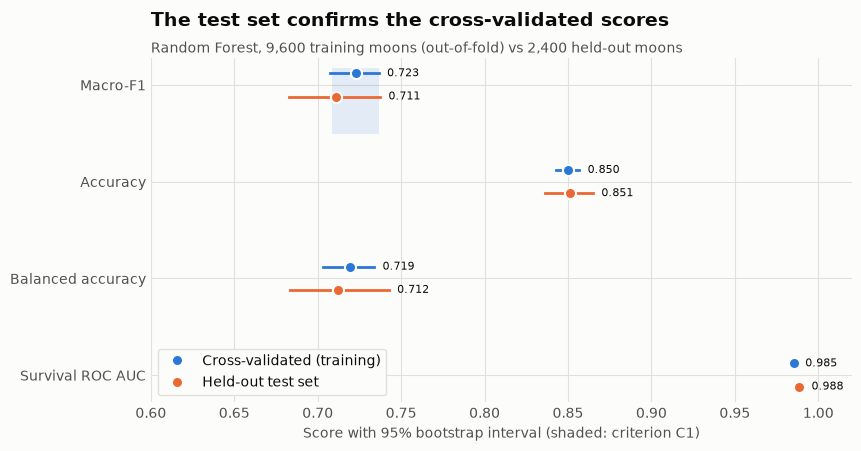

In [4]:
figs.test_vs_cv(test, frame);
rows = []
for name in ("selected", "physics_rule", "majority"):
    m = test["metrics"][name]
    rows.append({"model": name, "macro-F1": round(m["macro_f1"], 3), "accuracy": round(m["accuracy"], 3),
                 "balanced accuracy": round(m["balanced_accuracy"], 3)})
pd.DataFrame(rows)

**Result.** Every metric on the test set matches its cross-validated estimate within the intervals:
accuracy 85.1% (cross-validated 85.0%), macro-F1 0.711 (0.723), survival ROC AUC 0.988 (0.985).
Retraining with five other seeds gives test macro-F1 between 0.709 and 0.716, so the result does not
depend on a lucky seed. The physics rule reaches 78.9% and the majority class 38.0%.

## 4. Errors and calibration

Per-class calibration error: {'survived': 0.019, 'ejected': 0.03, 'hit_earth': 0.017, 'moon_interaction': 0.028}


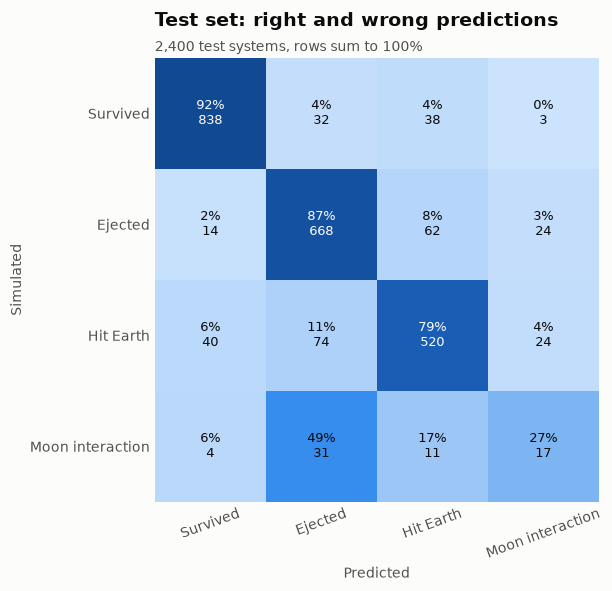

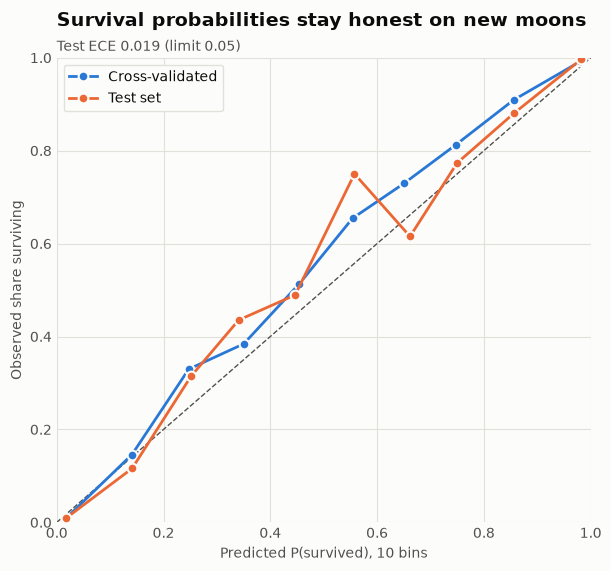

In [5]:
y = frame["y"].to_numpy()
prob = figs.probs(frame, "selected")
confusion(y, prob.argmax(axis=1), [LABELS[k] for k in config()["classes"]],
          "Test set: right and wrong predictions", f"{len(y):,} test systems, rows sum to 100%");
figs.calibration(test, frame);
print("Per-class calibration error:", {k: round(v, 3) for k, v in test["per_class_ece"].items()})

**Result.** The confusion matrix reproduces the cross-validated pattern: survivors 92%, ejections
87%, collisions with Earth 79%, Moon interactions 27% (17 of 63). The survival probabilities stay
close to the diagonal, and every class is calibrated to within 0.03.

## 5. Chaos and failures (rule T5)

After the evaluation was committed, 600 random test systems were simulated again with the second
moon displaced by 1 m (`configs/twins_test_1m.json`). **Rule T5**, the out-of-sample version of rule
P5: errors concentrate on chaotic systems if the error rate on twin-disagreeing systems exceeds that on
twin-agreeing systems (interval above zero).

Twin agreement 91.3% (survival alone 97.8%); 52 chaotic systems
Error on chaotic systems 53.8%, on stable systems 11.3%; difference 95% +0.283 to +0.561


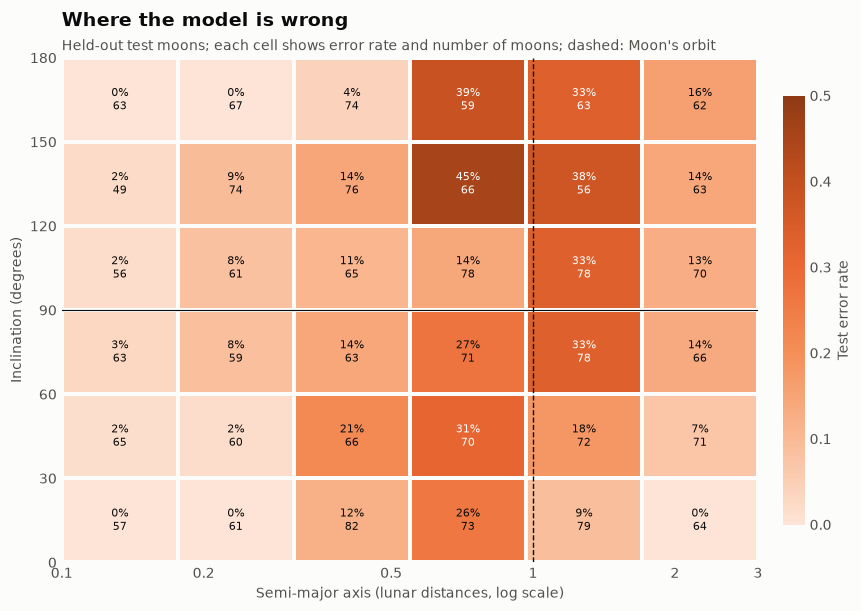

In [6]:
t5 = analysis["T5"]
print(f"Twin agreement {t5['agreement']:.1%} (survival alone {t5['binary_agreement']:.1%}); {t5['chaotic_moons']} chaotic systems")
print(f"Error on chaotic systems {t5['error_chaotic']:.1%}, on stable systems {t5['error_stable']:.1%}; "
      f"difference 95% {t5['difference_interval'][0]:+.3f} to {t5['difference_interval'][1]:+.3f}")
figs.error_map(analysis);

**Result.** Rule T5 is met: the model errs on 53.8% of the systems whose outcome a 1 m nudge changes,
and on 11.3% of the others. The error map locates the failures near the Moon's orbit (0.55–1.7 lunar
distances), with error rates of 26% to 45%. Close-in systems are almost never misclassified. The
failures coincide with the region where the simulation itself is least reproducible.

## 6. Confidence

If the model may set aside its least confident predictions, how accurate is it on the rest?

keep 50%: accuracy 98.2% (confidence at least 0.89)
keep 80%: accuracy 91.8% (confidence at least 0.61)
keep 90%: accuracy 88.5% (confidence at least 0.51)
keep 100%: accuracy 85.1% (confidence at least 0.30)


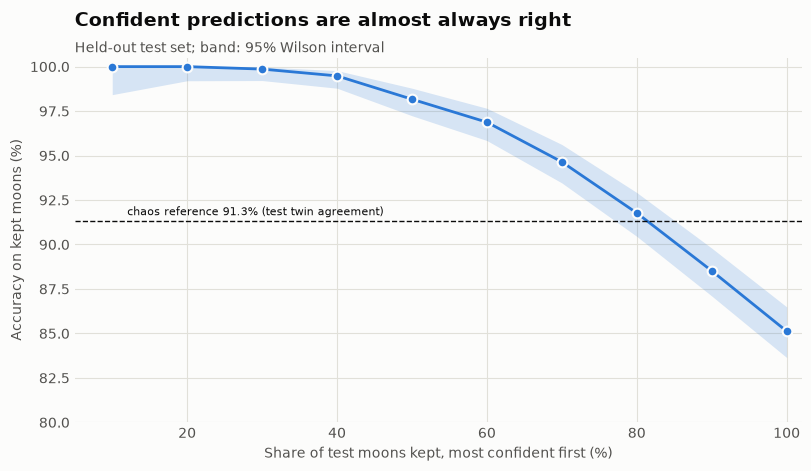

In [7]:
figs.coverage(analysis);
for point in analysis["coverage_accuracy"]:
    if point["coverage"] in (0.5, 0.8, 0.9, 1.0):
        print(f"keep {point['coverage']:.0%}: accuracy {point['accuracy']:.1%} (confidence at least {point['min_confidence']:.2f})")

**Result.** The most confident half of the test predictions is 98.2% correct, and the most confident
80% is 91.8% correct, comparable to the reproducibility of the simulation itself. The predicted
probability is therefore a useful signal of when to trust the surrogate and when to simulate.

## 7. Speed

The model and the simulation were timed single-threaded in one process on the same machine
(`src/benchmark_speed.py`, 100 training systems re-simulated).

Model: 111 ms for one system, 133 microseconds per system in batches
Simulation: median 2.67 s, mean 10.72 s (all 100 outcomes reproduced: True)
Speedup: 24x (median), 97x (mean), about 80,000x in batches; pre-registered 13x
Break-even after about 7,055 predictions


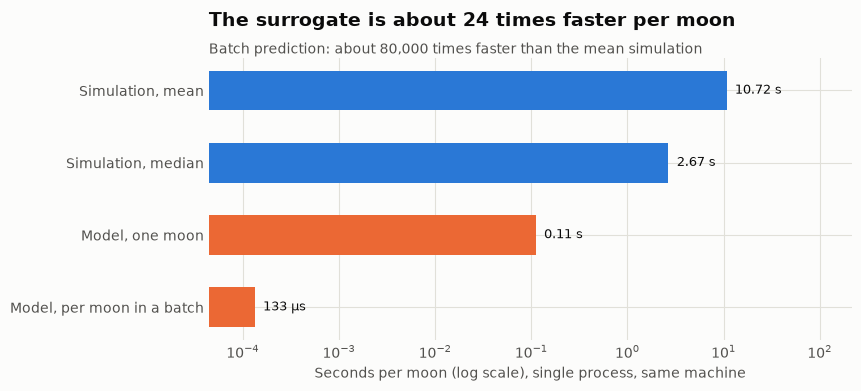

In [8]:
figs.speedup(speed);
s, sim, model = speed["speedup"], speed["simulation"], speed["model"]
print(f"Model: {model['latency_median_s'] * 1000:.0f} ms for one system, {model['batch_per_moon_s'] * 1e6:.0f} microseconds per system in batches")
print(f"Simulation: median {sim['median_s']:.2f} s, mean {sim['mean_s']:.2f} s (all 100 outcomes reproduced: {sim['all_outcomes_reproduced']})")
print(f"Speedup: {s['same_machine_median']:.0f}x (median), {s['same_machine_mean']:.0f}x (mean), about {figs.rounded(s['batch_vs_mean'])}x in batches; pre-registered {s['preregistered_median']:.0f}x")
print(f"Break-even after about {speed['break_even_predictions']:,.0f} predictions")

**Result.** One prediction takes 111 ms, against a median of 2.7 s and a mean of 10.7 s for one
simulation (survivors, which run the full 100 years, take about 20 s). The surrogate is 24 times
faster than the median simulation for single predictions and about 80,000 times faster than the mean
simulation in batches: all 12,000 systems would be classified in under two seconds, against 20.8
CPU-hours of simulation. Counting the cost of its training data, it pays off after about 7,000
predictions. The pre-registered comparison, against the 1.456 s median measured during dataset
generation with four parallel workers, gives a factor of 13.

## 8. The prediction tool

`src/predict.py` uses the evaluated model. Three examples: the second moon of notebook 01 (circular,
in the ecliptic, 0.4 lunar distances), the same orbit tilted to 90°, and a retrograde orbit beyond the
Moon.

In [9]:
examples = {
    "notebook 01 moon (0.4 lunar distances, i = 0°)": dict(mass_lunar=0.1, distance_lunar=0.4, eccentricity=0.0, inclination_deg=0),
    "same orbit tilted to 90°": dict(mass_lunar=0.1, distance_lunar=0.4, eccentricity=0.0, inclination_deg=90),
    "retrograde beyond the Moon (1.5 lunar distances, i = 160°)": dict(mass_lunar=0.5, distance_lunar=1.5, eccentricity=0.2, inclination_deg=160),
}
rows = []
for name, settings in examples.items():
    result = predict(**settings)
    rows.append({"system": name, **{k: f"{v:.0%}" for k, v in result["outcome"].items()}})
pd.DataFrame(rows).set_index("system")

,survived,ejected,hit_earth,moon_interaction
system,,,,
"notebook 01 moon (0.4 lunar distances, i = 0°)",91%,3%,4%,2%
same orbit tilted to 90°,10%,1%,88%,2%
"retrograde beyond the Moon (1.5 lunar distances, i = 160°)",13%,22%,29%,36%


**Result.** The flat close-in orbit is predicted to survive (91%), consistent with its 1,000-year
integration in Phase 3; tilting it to 90° makes a collision with Earth most likely (88%), the
Lidov–Kozai effect; the retrograde orbit beyond the Moon lies in the chaotic region and receives no
dominant outcome.

## Summary

- On 2,400 systems never used for any decision, the Random Forest reaches 85.1% accuracy and macro-F1
  0.711, matching its cross-validated estimates; all pre-registered criteria are met.
- It beats a two-variable physics rule (78.9%) and the majority class (38.0%), and its survival
  probabilities are calibrated (ECE 0.019; ROC AUC 0.988).
- Its errors concentrate on chaotic systems near the Moon's orbit; its confident predictions are
  almost always right.
- It is 24 times faster than a median simulation per prediction and about 80,000 times faster in
  batches, repaying its training data after about 7,000 predictions.